# 18 · Confounded action effects: sound rows from several logging regimes

A doctor decides the treatment of a patient after seeing something the data
do not record: the patient's hidden **strength** `W`.  Strong patients get the
aggressive treatment more often, and they also recover better on their own.
The logged table `P(h' | h, a)` then mixes the effect of the treatment with the
effect of strength: it is not `P(h' | h, do(a))`, the row a planner needs.

We have data from two regimes: the doctor (confounded) and a small
**randomised trial** (a coin decides the treatment).  `confounded_interval_set`
turns them into interval rows that contain `P(h' | h, do(a))` with probability
at least 95%, under declared assumptions.

Ground truth (hidden from the learner):

    W ~ Bernoulli(0.4) fresh at every step            (strong)
    doctor:  P(a = 1 | W = 1) = 0.8,  P(a = 1 | W = 0) = 0.1
    trial:   P(a = 1) = 0.5
    h' = clip(h + step, 0, 3),  step = +1 w.p. p(a, W), -1 otherwise
    p(1, strong) = 0.9, p(1, weak) = 0.3, p(0, strong) = 0.7, p(0, weak) = 0.5

- **NBN API:** `nbn.uncertainty.confounded_interval_set`, `confounding_gate`; `nbn.scm.context_invariance_test`.
- **Runtime:** under 20 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"` (the LP needs SciPy: `nbn[bounds]`), then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn import NeuralBayesianNetwork
from nbn.scm import StructuralCausalModel, context_invariance_test
from nbn.uncertainty import confounded_interval_set, confounding_gate, count_table
from nbn.utils.device import resolve_device

device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})

P_UP = torch.tensor([[0.5, 0.7], [0.3, 0.9]])     # [a, W]: probability of a step up
P_STRONG = 0.4
TREAT = {0: torch.tensor([0.1, 0.8]), 1: torch.tensor([0.5, 0.5])}   # regime -> P(a=1 | W)


def simulate(n_per_regime: int, seed: int) -> dict:
    g = torch.Generator().manual_seed(seed)
    rows = {"h": [], "a": [], "h'": [], "regime": []}
    for k, treat in TREAT.items():
        h = torch.randint(0, 4, (n_per_regime,), generator=g)
        w = torch.bernoulli(torch.full((n_per_regime,), P_STRONG), generator=g).long()
        a = torch.bernoulli(treat[w], generator=g).long()
        up = torch.bernoulli(P_UP[a, w], generator=g)
        rows["h"].append(h)
        rows["a"].append(a)
        rows["h'"].append((h + torch.where(up == 1, 1, -1)).clamp(0, 3))
        rows["regime"].append(torch.full((n_per_regime,), k))
    return {k: torch.cat(v).float() if k != "regime" else torch.cat(v) for k, v in rows.items()}


def interventional_table() -> torch.Tensor:
    """P(h' | h, do(a)) as [h, a, h'] (W averaged out with its own law, not the logger's)."""
    table = torch.zeros(4, 2, 4)
    p_w = torch.tensor([1 - P_STRONG, P_STRONG])
    for h in range(4):
        for a in range(2):
            up = float((P_UP[a] * p_w).sum())
            table[h, a, min(h + 1, 3)] += up
            table[h, a, max(h - 1, 0)] += 1 - up
    return table


data = simulate(3000, seed=0)
data = {k: v.to(device) for k, v in data.items()}
TRUTH = interventional_table()


def truth_inside(lo: torch.Tensor, hi: torch.Tensor, tol: float = 1e-6) -> bool:
    """Whether every entry of the true interventional table lies in [lo, hi]."""
    return bool(((TRUTH - lo).min() >= -tol) and ((hi - TRUTH).min() >= -tol))
model = NeuralBayesianNetwork([("h", "h'"), ("a", "h'")],
                              {"h": ("discrete", 4), "a": ("discrete", 2), "h'": ("discrete", 4)},
                              device=device)

device: cpu


## 1. The naive table is wrong

The doctor's data alone make the aggressive treatment look much better than it
is: the treated patients are mostly the strong ones.

In [2]:
doctor = {k: v[data["regime"] == 0] for k, v in data.items()}
counts, _ = count_table(model, doctor, "h'")
naive = (counts / counts.sum(-1, keepdim=True)).reshape(4, 2, 4).cpu()
h = 1
print(f"P(h'=2 | h=1, a=1): doctor's table {naive[h, 1, 2]:.3f}   truth P(h'=2 | h=1, do(a=1)) {TRUTH[h, 1, 2]:.3f}")
print(f"P(h'=2 | h=1, a=0): doctor's table {naive[h, 0, 2]:.3f}   truth P(h'=2 | h=1, do(a=0)) {TRUTH[h, 0, 2]:.3f}")

P(h'=2 | h=1, a=1): doctor's table 0.810   truth P(h'=2 | h=1, do(a=1)) 0.540
P(h'=2 | h=1, a=0): doctor's table 0.515   truth P(h'=2 | h=1, do(a=0)) 0.580


## 2. The gate

Is the action effect possibly confounded?  Nobody declared the doctor
unconfounded, so yes.  The invariance test (regime as context) agrees here: the
two regimes give different `P(h' | h, a)`.  A test that passes would *not*
prove the opposite: there is no statistical test for confounding.

In [3]:
scm = StructuralCausalModel([("h", "h'"), ("a", "h'")],
                            {"h": ("discrete", 4), "a": ("discrete", 2), "h'": ("discrete", 4),
                             "regime": ("discrete", 2)}, device=device)
test = context_invariance_test(scm, data, "h'", context="regime")
gate = confounding_gate(declared_unconfounded=False, invariance=test)
print(f"invariance test p = {test.p_value:.2g} | use confounded rows: {gate.use_confounded_rows}")
print("reason:", gate.reason)

invariance test p = 1.1e-46 | use confounded rows: True
reason: context invariance rejected (p = 1.06e-46 < 0.05): confounding or a changed mechanism; use the confounded rows


## 3. Sound rows, three ways

* **intersection** — the natural (Manski) row of each regime, intersected;
* **lp** — the instrumental-variable linear program over response types;
* **lp + declared trial** — the same program, told that regime 1 is randomised.

All three contain the truth (with probability at least 95%); the declared
trial pins the rows down.

In [4]:
variants = {
    "intersection": dict(method="intersection"),
    "lp": dict(method="lp"),
    "lp + declared trial": dict(method="lp", declared_unconfounded=[1]),
}
results = {name: confounded_interval_set(model, data, "h'", "a", "regime", delta=0.05, **kw)
           for name, kw in variants.items()}
for name, res in results.items():
    lo, hi = (t.reshape(4, 2, 4).cpu() for t in res.set.bounds())
    inside = truth_inside(lo, hi)
    print(f"{name:20s} mean width {float((hi - lo).mean()):.3f}   truth inside: {inside}   "
          f"methods {sorted(set(res.method_used))}")

intersection         mean width 0.532   truth inside: True   methods ['intersection']
lp                   mean width 0.532   truth inside: True   methods ['lp']
lp + declared trial  mean width 0.185   truth inside: True   methods ['lp']


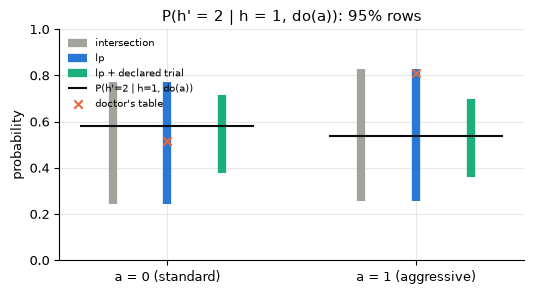

In [5]:
h, k = 1, 2
fig, ax = plt.subplots(figsize=(6, 3))
for i, ((name, res), color) in enumerate(zip(results.items(), (GREY, BLUE, AQUA))):
    lo, hi = (t.reshape(4, 2, 4).cpu() for t in res.set.bounds())
    for a in (0, 1):
        x = a + (i - 1) * 0.22
        ax.vlines(x, lo[h, a, k], hi[h, a, k], color=color, lw=6, label=name if a == 0 else None)
ax.hlines(TRUTH[h, :, k], [-0.35, 0.65], [0.35, 1.35], color=INK, lw=1.5, label="P(h'=2 | h=1, do(a))")
ax.scatter([0, 1], naive[h, :, k], marker="x", color=ORANGE, zorder=3, label="doctor's table")
ax.set(xticks=[0, 1], xticklabels=["a = 0 (standard)", "a = 1 (aggressive)"], ylabel="probability",
       ylim=(0, 1), title="P(h' = 2 | h = 1, do(a)): 95% rows")
ax.legend(frameon=False, fontsize=7, loc="upper left")
plt.show()

## 4. When the regimes cannot share one environment

If the two regimes ran in different environments, no single interventional
row may explain both.  Here the doctor's patients always improve and the
trial's always get worse.  For `a = 0`, the doctor's data say
`P(up | do(a=0)) >= P_doctor(a=0, up) = 0.62` and the trial's say
`P(down | do(a=0)) >= P_trial(a=0, down) = 0.50`: the two lower bounds add up to
more than 1 (the instrumental inequality).  With enough data the confidence
box is narrower than that violation (with little data it may hide it), and
the result says so for every configuration (`refuted`, the whole simplex)
instead of widening silently.

In [6]:
def shifted(seed: int) -> dict:
    d = simulate(20000, seed)               # enough data: the box must be narrower than the violation
    trial = d["regime"] == 1
    up, down = (d["h"] + 1).clamp(0, 3), (d["h"] - 1).clamp(0, 3)
    d["h'"] = torch.where(trial, down, up)          # doctor's patients always up, the trial's always down
    return {k: v.to(device) for k, v in d.items()}


bad = confounded_interval_set(model, shifted(1), "h'", "a", "regime", method="intersection", delta=0.05)
print("refuted configurations of h:", bad.refuted.tolist())
print(bad.notes[0] if bad.notes else "")

refuted configurations of h: [True, True, True, True]
configuration 0 of ('h',): empty intersection of per-regime rows


## 5. Do the rows keep their promise?

Over 20 fresh datasets, the rows of every `(h, a)` should contain the truth
together in at least 95% of them.

In [7]:
hits = 0
for r in range(20):
    d = {k: v.to(device) for k, v in simulate(3000, seed=100 + r).items()}
    res = confounded_interval_set(model, d, "h'", "a", "regime", method="lp", delta=0.05,
                                  declared_unconfounded=[1])
    lo, hi = (t.reshape(4, 2, 4).cpu() for t in res.set.bounds())
    hits += int(truth_inside(lo, hi))
print(f"every row contained the truth in {hits}/20 datasets (promise: at least 95%)")

every row contained the truth in 20/20 datasets (promise: at least 95%)


The declared assumptions are part of the result (`res.assumptions`): one
environment for both regimes, the regime independent of the hidden strength
given `h`, fresh confounding (a new `W` at every step), and the trial really
randomised.  With **persistent** hidden state the per-step rows are not valid.